# Proyecto final · 05 · Evaluación

Tercera etapa del pipeline. Primero se elige el modelo entre los cuatro entrenamientos, mirando solo `dev_seleccion`. Después se mide **una sola vez** el modelo elegido en los conjuntos que nadie usó para decidir nada: el test de FCE y los hispanohablantes de dev y de test, reportados por separado.

```mermaid
flowchart LR
    A[4 entrenamientos<br/>base ×3 tasas · large] -->|F0.5 en dev_seleccion| B[modelo elegido]
    B --> C[corregir.py<br/>beam search de 4]
    C --> D[fce_test · 2.695]
    C --> E[fce_dev_es · 533]
    C --> F[fce_test_es · 224]
    D & E & F --> G[ERRANT<br/>F0.5 global y por tipo]
```

Toda la medición pasa por `src/evaluacion.py` y toda la corrección por `src/corregir.py` (los dos con tests). La app usará ese mismo `Corrector`.

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ / "src"))
import evaluacion
from corregir import Corrector
from graficas import AZUL, NARANJA, TINTA_SECUNDARIA, aplicar_estilo
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()

DATOS, MODELOS, FIG = RAIZ / "datos" / "procesados" / "entrenamiento", RAIZ / "modelos", RAIZ / "figuras"
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
aplicar_estilo()
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU")

NVIDIA GeForce RTX 4060 Ti


## 1 · Selección del modelo en dev

Se entrenaron cuatro variantes con el mismo `src/entrenar.py`. El primer modelo (notebook 04) quedó en F0.5 = 0,503; para mejorarlo se probó primero lo barato y después un modelo más grande:

- **otra tasa de aprendizaje** con BART-base (1e-5 y 5e-5);
- **BART-large** (406 M parámetros, tres veces BART-base), con los mismos hiperparámetros y lote efectivo 32 (16 × 2 de acumulación de gradiente).

También se probó corregir en varias pasadas (la salida vuelve a entrar al modelo, `Corrector.corregir(pasadas=3)`): con BART-base dio 0,5025 → 0,5016 → 0,5017, así que se descartó.

Cada entrenamiento dejó su `registro.jsonl` con F0.5 por época:

In [2]:
CORRIDAS = {
    "BART-base · 3e-5 (notebook 04)": MODELOS / "bart-base-gec",
    "BART-base · 1e-5": MODELOS / "experimentos" / "base-1e-5",
    "BART-base · 5e-5": MODELOS / "experimentos" / "base-5e-5",
    "BART-large · 3e-5": MODELOS / "experimentos" / "large-3e-5",
}

def evaluaciones(carpeta):
    filas = [json.loads(l) for l in (carpeta / "registro.jsonl").read_text().splitlines()]
    return pd.DataFrame([f for f in filas if "eval_f05" in f])

curvas = {nombre: evaluaciones(c) for nombre, c in CORRIDAS.items()}
seleccion = pd.DataFrame([
    {"corrida": nombre, "épocas": int(d.epoca.max()), "mejor época": int(d.loc[d.eval_f05.idxmax(), "epoca"]),
     "F0.5": d.eval_f05.max(), "precisión": d.loc[d.eval_f05.idxmax(), "eval_precision"],
     "recall": d.loc[d.eval_f05.idxmax(), "eval_recall"]}
    for nombre, d in curvas.items()
]).set_index("corrida")
seleccion.style.format({"F0.5": "{:.4f}", "precisión": "{:.3f}", "recall": "{:.3f}"}).highlight_max(subset=["F0.5"], color="#d6e8fa")

,épocas,mejor época,F0.5,precisión,recall
corrida,,,,,
BART-base · 3e-5 (notebook 04),5,2,0.5029,0.597,0.308
BART-base · 1e-5,10,7,0.5052,0.587,0.324
BART-base · 5e-5,5,2,0.5008,0.586,0.317
BART-large · 3e-5,6,3,0.5314,0.588,0.383


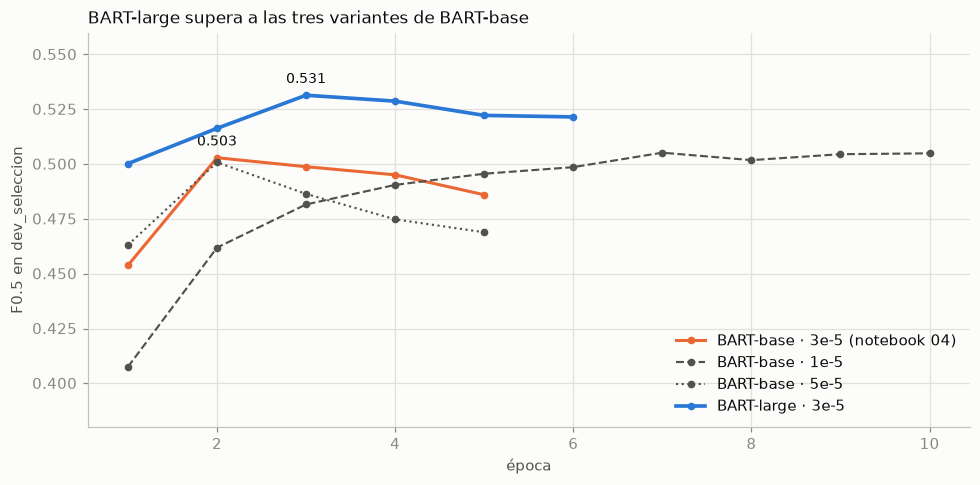

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
estilos = {
    "BART-large · 3e-5": dict(color=AZUL, lw=2.4, zorder=3),
    "BART-base · 3e-5 (notebook 04)": dict(color=NARANJA, lw=2),
    "BART-base · 1e-5": dict(color=TINTA_SECUNDARIA, lw=1.4, ls="--"),
    "BART-base · 5e-5": dict(color=TINTA_SECUNDARIA, lw=1.4, ls=":"),
}
for nombre, d in curvas.items():
    d = d[d.epoca > 0]
    ax.plot(d.epoca, d.eval_f05, marker="o", ms=4, label=nombre, **estilos[nombre])
    mejor = d.loc[d.eval_f05.idxmax()]
    if nombre in ("BART-large · 3e-5", "BART-base · 3e-5 (notebook 04)"):
        ax.annotate(f"{mejor.eval_f05:.3f}", (mejor.epoca, mejor.eval_f05), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=9)
ax.set(xlabel="época", ylabel="F0.5 en dev_seleccion", title="BART-large supera a las tres variantes de BART-base",
       ylim=(0.38, 0.56))
ax.legend(loc="lower right", frameon=False)
fig.tight_layout()
fig.savefig(FIG / "17_seleccion_modelo.png")
plt.show()

Cambiar la tasa no mueve a BART-base de 0,50: con 1e-5 llega más lento al mismo punto y con 5e-5 se pasa antes. El tamaño sí: BART-large conserva la precisión (≈ 0,59) y encuentra más errores (recall 0,38 contra 0,31). Todas las corridas comparten el patrón del notebook 04: tras el mejor punto el recall sigue subiendo pero la precisión cae más rápido, y la parada temprana corta.

**Modelo elegido: BART-large, época 3.** BART-base (notebook 04) se mide también en test como referencia, pero la decisión ya quedó tomada en dev.

## 2 · Medición final

Para cada conjunto se mide F0.5 de cuatro salidas:

- **copiar**: devolver la oración sin cambios; es la línea base y da 0 (no acierta ninguna corrección);
- **BART-base** y **BART-large**: lo que genera cada modelo con beam search de 4;
- **techo**: la corrección de referencia pasada por el mismo camino (destokenizar → spaCy → ERRANT). No llega a 1 porque ERRANT, al reextraer las ediciones, no siempre las corta igual que los anotadores (notebook 02, P5).

In [4]:
CONJUNTOS = {
    "fce_test": "FCE test, todos los autores",
    "fce_dev_es": "FCE dev, hispanohablantes",
    "fce_test_es": "FCE test, hispanohablantes",
}
conjuntos = {c: evaluacion.leer_conjunto(DATOS / c) for c in CONJUNTOS}
correctores = {
    "BART-base": Corrector(MODELOS / "bart-base-gec" / "mejor"),
    "BART-large": Corrector(MODELOS / "experimentos" / "large-3e-5" / "mejor"),
}
salidas = {
    (c, m): corrector.corregir([f["original"] for f in conj.entrada])[0]
    for c, conj in conjuntos.items() for m, corrector in correctores.items()
}
print({c: len(conj) for c, conj in conjuntos.items()})

{'fce_test': 2695, 'fce_dev_es': 533, 'fce_test_es': 224}


In [5]:
filas = []
for c, conj in conjuntos.items():
    textos = {"copiar": [f["original"] for f in conj.entrada],
              "BART-base": salidas[c, "BART-base"], "BART-large": salidas[c, "BART-large"],
              "techo": [f["corregida"] for f in conj.entrada]}
    for sistema, t in textos.items():
        r = evaluacion.f05(conj, evaluacion.tokenizar(t))
        filas.append({"conjunto": CONJUNTOS[c], "oraciones": len(conj), "sistema": sistema, **r})
resultados = pd.DataFrame(filas)
tabla = resultados.pivot(index=["conjunto", "oraciones"], columns="sistema", values="f05")[["copiar", "BART-base", "BART-large", "techo"]]
tabla.style.format("{:.3f}")

,sistema,copiar,BART-base,BART-large,techo
conjunto,oraciones,,,,
"FCE dev, hispanohablantes",533,0.000,0.486,0.519,0.844
"FCE test, hispanohablantes",224,0.000,0.471,0.515,0.853
"FCE test, todos los autores",2695,0.000,0.495,0.525,0.855


In [6]:
detalle = resultados[resultados.sistema == "BART-large"].set_index("conjunto")[["tp", "fp", "fn", "precision", "recall", "f05"]]
detalle.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f05": "{:.3f}"})

,tp,fp,fn,precision,recall,f05
conjunto,,,,,,
"FCE test, todos los autores",1696,1202,2853,0.585,0.373,0.525
"FCE dev, hispanohablantes",361,268,600,0.574,0.376,0.519
"FCE test, hispanohablantes",225,168,387,0.573,0.368,0.515


La tabla de arriba es el resultado del proyecto: **BART-large logra F0.5 = 0,525 en FCE test**, prácticamente lo mismo que en dev (0,531), así que la selección no sobreajustó a dev. Supera a BART-base en los tres conjuntos (+3 a +4 puntos) y recorre cerca del 60 % del camino entre copiar (0) y el techo de la anotación (≈ 0,85).

El detalle de BART-large (TP: correcciones acertadas, FP: cambios que la referencia no pide, FN: errores que se le escapan) muestra que la precisión se sostiene fuera de dev (0,57–0,59), que es lo que importa para la app: cuando el corrector propone un cambio, la mayoría de las veces coincide con lo que haría el anotador. El recall (≈ 0,37) dice que deja sin tocar cerca de 6 de cada 10 errores.

Los hispanohablantes quedan apenas por debajo del total (0,519 y 0,515 contra 0,525): el modelo, entrenado con autores de todas las lenguas, les sirve igual. Son conjuntos pequeños (533 y 224 oraciones, de 44 y 20 textos), así que una diferencia de un punto está dentro de lo que cambia con unos pocos textos; por eso se reportan por separado y no se mezclan con dev ni con test.

## 3 · F0.5 por tipo de error

`evaluacion.f05_por_tipo` corre `errant_compare -cat 2`: cruza las mismas ediciones pero las agrupa por tipo de ERRANT sin la operación (`VERB:SVA` reúne lo que falta, sobra o se reemplaza en la concordancia sujeto-verbo). Se muestran los tipos con al menos 40 errores en la referencia de FCE test.

In [7]:
NOMBRES = {
    "PUNCT": "puntuación", "DET": "artículos y determinantes", "PREP": "preposiciones", "SPELL": "ortografía",
    "VERB": "verbo (palabra equivocada)", "VERB:TENSE": "tiempo verbal", "VERB:FORM": "forma verbal (infinitivo, -ing…)",
    "VERB:SVA": "concordancia sujeto-verbo", "NOUN": "sustantivo (palabra equivocada)", "NOUN:NUM": "singular / plural",
    "PRON": "pronombres", "ADJ": "adjetivos", "ADV": "adverbios", "ORTH": "mayúsculas y espacios", "MORPH": "morfología",
    "WO": "orden de palabras", "CONJ": "conjunciones", "PART": "partículas", "OTHER": "otros (reescrituras)",
    "NOUN:POSS": "posesivo", "CONTR": "contracciones", "VERB:INFL": "conjugación mal formada", "ADJ:FORM": "comparativos",
}

def por_tipo(c, sistema):
    tipos = evaluacion.f05_por_tipo(conjuntos[c], evaluacion.tokenizar(salidas[c, sistema]))
    d = pd.DataFrame(tipos).T
    d["errores"] = d.tp + d.fn
    return d

tipos = por_tipo("fce_test", "BART-large")
frecuentes = tipos[tipos.errores >= 40].sort_values("errores", ascending=False)
frecuentes.insert(0, "qué es", frecuentes.index.map(lambda t: NOMBRES.get(t, "")))
frecuentes[["qué es", "errores", "tp", "fp", "fn", "precision", "recall", "f05"]].style.format(
    {"errores": "{:.0f}", "tp": "{:.0f}", "fp": "{:.0f}", "fn": "{:.0f}", "precision": "{:.2f}", "recall": "{:.2f}", "f05": "{:.2f}"})

,qué es,errores,tp,fp,fn,precision,recall,f05
DET,artículos y determinantes,625,298,138,327,0.68,0.48,0.63
OTHER,otros (reescrituras),580,103,219,477,0.32,0.18,0.28
PREP,preposiciones,477,202,105,275,0.66,0.42,0.59
PUNCT,puntuación,471,204,252,267,0.45,0.43,0.44
SPELL,ortografía,452,249,39,203,0.86,0.55,0.78
VERB,verbo (palabra equivocada),243,42,63,201,0.40,0.17,0.32
VERB:TENSE,tiempo verbal,232,68,65,164,0.51,0.29,0.45
ORTH,mayúsculas y espacios,214,82,25,132,0.77,0.38,0.64
NOUN,sustantivo (palabra equivocada),202,24,79,178,0.23,0.12,0.20
NOUN:NUM,singular / plural,174,84,27,90,0.76,0.48,0.68


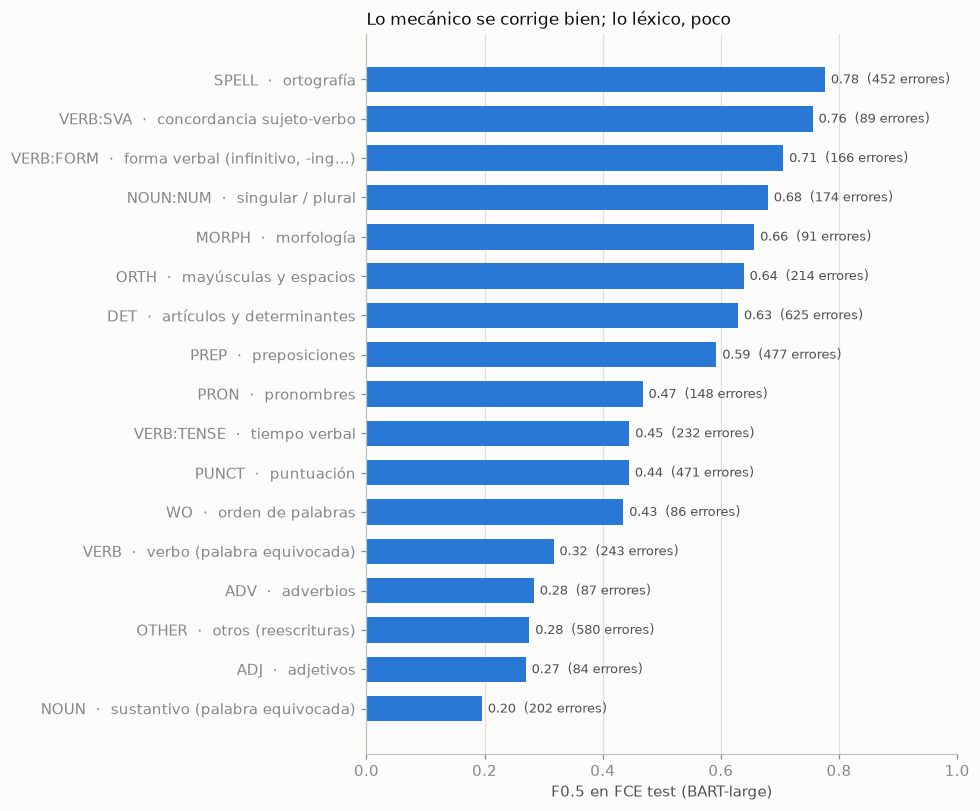

In [8]:
orden = frecuentes.sort_values("f05")
fig, ax = plt.subplots(figsize=(9, 0.38 * len(orden) + 1))
ax.barh([f"{t}  ·  {NOMBRES.get(t, '')}" for t in orden.index], orden.f05, color=AZUL, height=0.65)
for i, (f, n) in enumerate(zip(orden.f05, orden.errores)):
    ax.text(f + 0.01, i, f"{f:.2f}  ({n:.0f} errores)", va="center", fontsize=8.5, color=TINTA_SECUNDARIA)
ax.set(xlim=(0, 1), xlabel="F0.5 en FCE test (BART-large)", title="Lo mecánico se corrige bien; lo léxico, poco")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "18_f05_por_tipo.png")
plt.show()

Hay tres franjas:

- **Fuertes (F0.5 ≥ 0,6)**: ortografía (0,78), concordancia sujeto-verbo (0,76), forma verbal (0,71), singular/plural (0,68), morfología, mayúsculas y artículos. Son errores con una regla clara: el contexto alcanza para decidir y la precisión pasa de 0,68.
- **Medios (0,4–0,6)**: preposiciones (0,59), pronombres, tiempo verbal, puntuación y orden de palabras. La puntuación es el caso típico: acierta 204 pero propone 252 cambios que la referencia no tiene, porque muchas comas son opcionales.
- **Débiles (< 0,35)**: elegir otro sustantivo (0,20), adjetivo, adverbio, verbo o reescribir (`OTHER`). Dependen del significado, hay muchas correcciones válidas y la referencia solo trae una, así que incluso un cambio razonable cuenta como FP.

Esto orienta la explicación de la app: en los tipos fuertes se puede afirmar la regla; en los débiles conviene presentarlo como sugerencia.

En los hispanohablantes de test (224 oraciones) los tipos más frecuentes son:

In [9]:
tipos_es = por_tipo("fce_test_es", "BART-large").sort_values("errores", ascending=False).head(8)
tipos_es.insert(0, "qué es", tipos_es.index.map(lambda t: NOMBRES.get(t, "")))
tipos_es[["qué es", "errores", "tp", "fp", "fn", "f05"]].style.format(
    {"errores": "{:.0f}", "tp": "{:.0f}", "fp": "{:.0f}", "fn": "{:.0f}", "f05": "{:.2f}"})

,qué es,errores,tp,fp,fn,f05
SPELL,ortografía,103,51,6,52,0.77
OTHER,otros (reescrituras),82,19,44,63,0.28
ORTH,mayúsculas y espacios,61,23,1,38,0.73
PUNCT,puntuación,60,21,37,39,0.36
PREP,preposiciones,56,24,14,32,0.58
DET,artículos y determinantes,44,16,11,28,0.53
VERB:FORM,"forma verbal (infinitivo, -ing…)",31,19,3,12,0.80
NOUN,sustantivo (palabra equivocada),31,1,12,30,0.06


## 4 · Ejemplos reales de hispanohablantes

Oraciones de `fce_test_es` en tres grupos, comparando la salida de BART-large con la referencia completa:

- **acierto completo**: la salida es idéntica a la referencia y había algo que corregir;
- **se le escapó**: la referencia corrige algo y el modelo devolvió la oración igual;
- **cambio de más**: la referencia no cambia nada y el modelo sí.

In [10]:
conj = conjuntos["fce_test_es"]
ej = pd.DataFrame({"original": [f["original"] for f in conj.entrada], "BART-large": salidas["fce_test_es", "BART-large"],
                   "referencia": [f["corregida"] for f in conj.entrada]})
norm = lambda s: " ".join(s.split())
ej["grupo"] = "parcial"
ej.loc[(ej.original != ej.referencia) & (ej["BART-large"].map(norm) == ej.referencia.map(norm)), "grupo"] = "acierto completo"
ej.loc[(ej.original != ej.referencia) & (ej["BART-large"].map(norm) == ej.original.map(norm)), "grupo"] = "se le escapó"
ej.loc[(ej.original == ej.referencia) & (ej["BART-large"].map(norm) != ej.original.map(norm)), "grupo"] = "cambio de más"
ej.loc[(ej.original == ej.referencia) & (ej["BART-large"].map(norm) == ej.original.map(norm)), "grupo"] = "correcta y la deja igual"
print(ej.grupo.value_counts().to_string())

grupo
parcial                     90
correcta y la deja igual    61
se le escapó                43
acierto completo            24
cambio de más                6


In [11]:
corta = ej[ej.original.str.len().between(30, 140)]
pd.concat([corta[corta.grupo == g].head(4) for g in ("acierto completo", "se le escapó", "cambio de más")])[["grupo", "original", "BART-large", "referencia"]]

,grupo,original,BART-large,referencia
9,acierto completo,"Finally, the last day I sugget you to go to the mall where you can enjoy shopping and looking around.","Finally, on the last day I suggest you go to the mall where you can enjoy shopping and looking around.","Finally, on the last day I suggest you go to the mall where you can enjoy shopping and looking around."
14,acierto completo,I asked to some pleople in town and this was the best place to choose.,I asked some people in town and this was the best place to choose.,I asked some people in town and this was the best place to choose.
19,acierto completo,"Is situated in the top of a little mountain in the ""old"" part on the city.","It is situated on the top of a little mountain in the ""old"" part of the city.","It is situated on the top of a little mountain in the ""old"" part of the city."
55,acierto completo,You have been booked to stay in the Palace Hotel which is a very pleasant hotel not far away from here.,"You have been booked to stay in the Palace Hotel, which is a very pleasant hotel not far away from here.","You have been booked to stay in the Palace Hotel, which is a very pleasant hotel not far away from here."
7,se le escapó,The party is going to be in a local discotheque near the college so the best way to get there is walking.,The party is going to be in a local discotheque near the college so the best way to get there is walking.,The party is going to be in a local discotheque near the college so the best way to get there is to walk.
13,se le escapó,This is an historical building.,This is an historical building.,This is a historical building.
18,se le escapó,The Musseum is situated in front of the sea in the centre of Acapulco.,The Musseum is situated in front of the sea in the centre of Acapulco.,The Museum is situated in front of the sea in the centre of Acapulco.
20,se le escapó,You are able to get there by car or walking and see everything which was made at that time.,You are able to get there by car or walking and see everything which was made at that time.,You are able to get there by car or on foot and see everything which was made at that time.
5,cambio de más,This has the best price that we could find.,This is the best price that we could find.,This has the best price that we could find.
65,cambio de más,If you go to the main street you will find a street full of shops and I am sure the students would like that.,"If you go to the main street, you will find a street full of shops and I am sure the students would like that.",If you go to the main street you will find a street full of shops and I am sure the students would like that.


- **Aciertos completos (24)**: oraciones con varios errores a la vez que el modelo deja exactamente como el anotador (*sugget you to go* → *suggest you go*, *on the city* → *of the city*).
- **Se le escapó (43)**: hay de dos clases. Reescrituras de estilo (*walking* → *on foot*), donde el modelo prefiere no tocar, que es el lado conservador que premia F0.5; y errores simples que sí debía ver (*Musseum*, *an historical*), que son el margen de mejora real.
- **Cambio de más (solo 6)**: de las 67 oraciones correctas, deja igual 61 (91 %), que es lo que necesita la app para no molestar. Y de esos 6, varios son correcciones válidas que el anotador no hizo: *that **is** was* → *that **it** was* es un acierto que la referencia omitió, y la coma tras *main street* es aceptable. El F0.5 con una sola referencia subestima la calidad real.
- **Parcial (90)**: corrige una parte de lo que pide la referencia.

## 5 · Velocidad para la app

La app corrige una oración a la vez mientras el usuario espera, así que importa la latencia con lote de 1, no el rendimiento por lotes.

In [12]:
muestras = [f["original"] for f in conjuntos["fce_test_es"].entrada if len(f["original"]) > 40][:30]
velocidad = []
for nombre, corrector in correctores.items():
    corrector.corregir(muestras[:2])  # calentar la GPU
    inicio = time.perf_counter()
    for s in muestras:
        corrector.corregir([s])
    velocidad.append({"modelo": nombre, "dispositivo": torch.cuda.get_device_name(0),
                      "ms por oración": 1000 * (time.perf_counter() - inicio) / len(muestras),
                      "memoria GPU (GB)": torch.cuda.max_memory_allocated() / 1e9})
pd.DataFrame(velocidad).style.format({"ms por oración": "{:.0f}", "memoria GPU (GB)": "{:.1f}"}).hide(axis="index")

modelo,dispositivo,ms por oración,memoria GPU (GB)
BART-base,NVIDIA GeForce RTX 4060 Ti,73,4.5
BART-large,NVIDIA GeForce RTX 4060 Ti,164,4.5


BART-large tarda unos 120 ms por oración en la torre: un párrafo de cinco oraciones se corrige en menos de un segundo, aceptable para una app interactiva. La memoria indicada es el pico del notebook, con los dos modelos cargados a la vez; la app solo carga BART-large.

## Resumen

| | |
|---|---|
| Selección | 4 entrenamientos comparados en `dev_seleccion`; BART-large (época 3) gana con F0.5 = 0,531 frente a 0,50 de BART-base con cualquier tasa; corregir en varias pasadas no ayuda |
| Resultado | **F0.5 = 0,525 en FCE test** (P 0,585 · R 0,373), contra 0 de copiar y un techo de 0,855; BART-base da 0,495 |
| Hispanohablantes | 0,519 en FCE dev y 0,515 en FCE test: igual que el total dentro del margen de conjuntos tan pequeños |
| Por tipo | fuerte en ortografía, concordancia, forma verbal y singular/plural (≥ 0,68); débil en elección de palabra y reescrituras (≤ 0,32) |
| Para la app | deja intactas el 91 % de las oraciones correctas; 120 ms por oración en la RTX 4060 Ti |
| Siguiente | `06_explicacion`: convertir cada edición de ERRANT en una explicación en español |